,temperature_c,energy_kwh
0,0,42
1,5,36
2,10,33
3,15,27
4,20,23
5,25,18


Зміна споживання на 1 °C (w): -0.85 кВт·год
Базове споживання (b): 39.88 кВт·год
Прогноз для 12 °C: 29.71 кВт·год


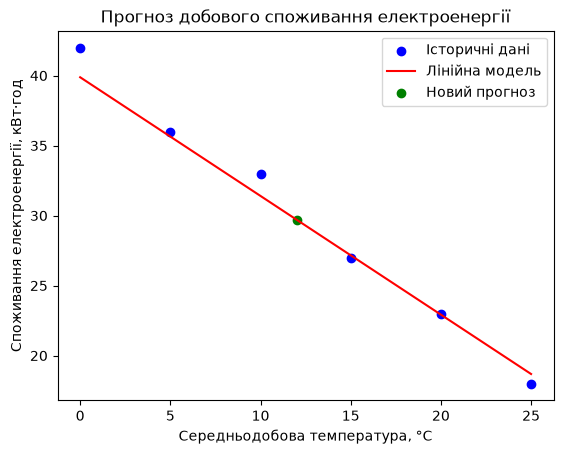

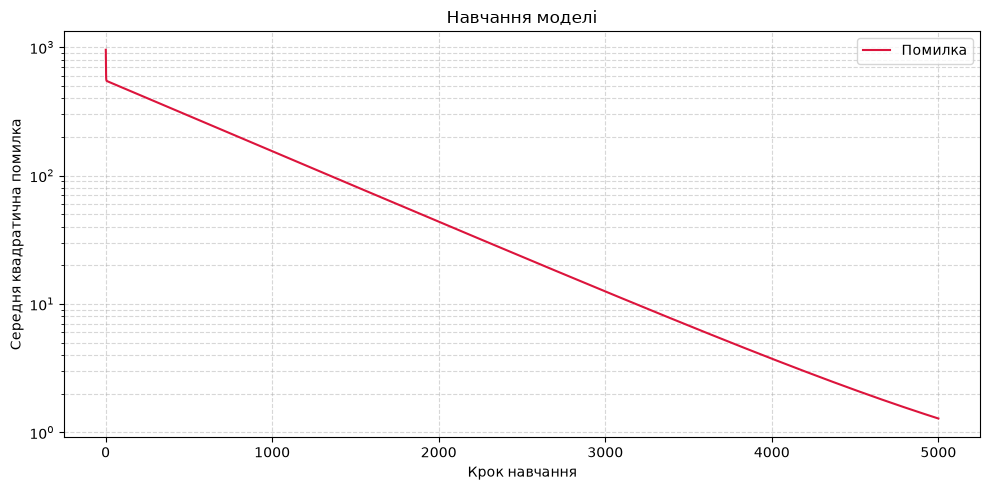

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.array([0, 5, 10, 15, 20, 25])
Y = np.array([42, 36, 33, 27, 23, 18])

data = pd.DataFrame({"temperature_c": X, "energy_kwh": Y})
display(data)

w = 0.0
b = 0.0
learning_rate = 0.001
epochs = 5000
n = len(X)
error_history = []

for epoch in range(epochs):
    y_pred = w * X + b
    error = y_pred - Y

    dw = (2 / n) * np.sum(error * X)
    db = (2 / n) * np.sum(error)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    error_history.append(np.mean(error ** 2))

print(f"Зміна споживання на 1 °C (w): {w:.2f} кВт·год")
print(f"Базове споживання (b): {b:.2f} кВт·год")

new_temperature = 12
predicted_energy = w * new_temperature + b
print(f"Прогноз для {new_temperature} °C: {predicted_energy:.2f} кВт·год")

plt.scatter(X, Y, color="blue", label="Історичні дані")
plt.plot(X, w * X + b, color="red", label="Лінійна модель")
plt.scatter(new_temperature, predicted_energy, color="green", label="Новий прогноз")
plt.xlabel("Середньодобова температура, °C")
plt.ylabel("Споживання електроенергії, кВт·год")
plt.title("Прогноз добового споживання електроенергії")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), error_history, color="crimson", label="Помилка")
plt.yscale("log")
plt.xlabel("Крок навчання")
plt.ylabel("Середня квадратична помилка")
plt.title("Навчання моделі")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()